# Notebook 02: the classic detectors on KDD99

**Class 03_01.** Ten detectors, one protocol (notebook 01): fit on normal training rows, threshold at 1% false
alarms on normal validation rows, test with 1.8% attacks. Every detector returns a score where higher = more anomalous.

| family | detector | score |
|:--|:--|:--|
| statistics | z-score, diagonal Gaussian, Mahalanobis | $\max_j\lvert z_j\rvert$, $\sum_j z_j^2$, $d_M^2$ |
| clustering | k-means (k = 20), Gaussian mixture (10 components) | distance to the nearest centre, $-\log p(\mathbf{x})$ |
| neighbours | kNN distance (k = 5), LOF (k = 20) | distance to the 5th neighbour, local density ratio |
| isolation | Isolation Forest (200 trees) | $2^{-E[h]/c(n)}$ |
| boundary | one-class SVM ($\nu=0.01$, RBF) | $-$ signed distance to the boundary |
| subspace | PCA (95% of the variance) | squared reconstruction error |

In [1]:
import sys
import time

import numpy as np
import polars as pl
from matplotlib import pyplot as plt

sys.path.insert(0, ".")
import plots_results as pr

import anomlib as an

plt.rcParams["figure.dpi"] = 100
an.table_config()
df = an.load_kdd()
sp = an.kdd_split(df, seed=0)
Xtr, Xva, Xte, y = sp.X("train"), sp.X("val"), sp.X("test"), sp.y_test
cats = sp.test["category"]

## A. One split, all detectors

In [2]:
rows, scores = [], {}
for det in an.zoo(seed=0):
    t0 = time.time()
    det.fit(Xtr)
    s_va, s_te = det.score(Xva), det.score(Xte)
    scores[det.name] = (s_va, s_te)
    rows.append({"detector": det.name, **an.evaluate(s_te, y, s_va), **an.recall_by_category(s_te, cats, s_va),
                 "seconds": time.time() - t0})  # fmt: skip
res = pl.DataFrame(rows)
print(res.sort("AUPRC", descending=True))
pr.ten_detectors(res.to_dicts())  # slide plots: assets/figures/plots/03/
pr.recall_cat(res.to_dicts())

┌───────────────────────┬───────┬───────┬────────┬───────────┬───────┬───────┬───────┬───────┬───────┬───────┬─────────┐
│ detector              ┆ AUROC ┆ AUPRC ┆ recall ┆ precision ┆ F1    ┆ FPR   ┆ dos   ┆ probe ┆ r2l   ┆ u2r   ┆ seconds │
╞═══════════════════════╪═══════╪═══════╪════════╪═══════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═════════╡
│ GMM (-log-likelihood) ┆ 0.982 ┆ 0.675 ┆ 0.702  ┆ 0.543     ┆ 0.612 ┆ 0.011 ┆ 1.000 ┆ 0.850 ┆ 0.250 ┆ 0.731 ┆ 0.844   │
│ One-class SVM         ┆ 0.980 ┆ 0.625 ┆ 0.721  ┆ 0.523     ┆ 0.606 ┆ 0.012 ┆ 1.000 ┆ 0.920 ┆ 0.240 ┆ 0.731 ┆ 0.954   │
│ Isolation Forest      ┆ 0.943 ┆ 0.622 ┆ 0.592  ┆ 0.479     ┆ 0.529 ┆ 0.012 ┆ 0.960 ┆ 0.890 ┆ 0.060 ┆ 0.077 ┆ 2.465   │
│ kNN distance          ┆ 0.989 ┆ 0.595 ┆ 0.715  ┆ 0.547     ┆ 0.620 ┆ 0.011 ┆ 0.990 ┆ 0.930 ┆ 0.220 ┆ 0.731 ┆ 1.063   │
│ PCA reconstruction    ┆ 0.982 ┆ 0.549 ┆ 0.776  ┆ 0.541     ┆ 0.637 ┆ 0.012 ┆ 0.970 ┆ 0.880 ┆ 0.450 ┆ 0.885 ┆ 1.434   │
│ Mahalanobis           ┆ 0.979 

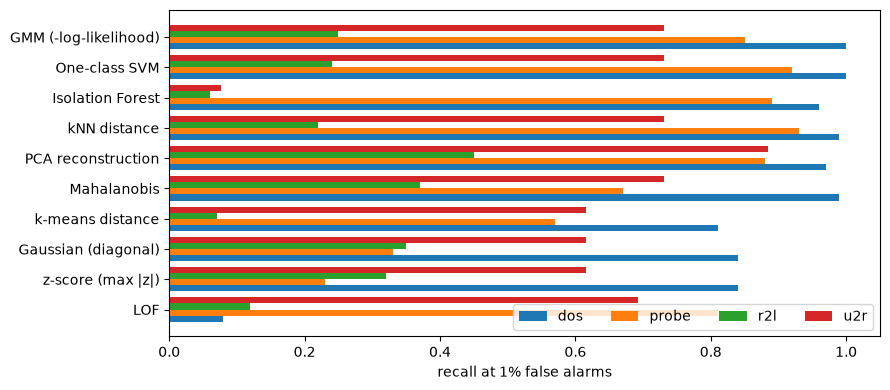

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
r = res.sort("AUPRC")
for i, c in enumerate(an.CATEGORIES):
    ax.barh(np.arange(len(r)) + (i - 1.5) * 0.2, r[c], height=0.2, label=c)
ax.set_yticks(np.arange(len(r)), r["detector"])
ax.set_xlabel("recall at 1% false alarms")
ax.legend(ncol=4, loc="lower right")
plt.tight_layout()
plt.show()

**Reading the table.**
* Every detector has AUROC above 0.94, but AUPRC between 0.33 and 0.68: the base rate at work.
* **dos and probe** are easy (volume and error-rate features move far from normal); **r2l** is hard for all of them:
  a password-guessing or warez connection looks like an ordinary login. It differs in content, not in shape.
* **LOF misses dos** (recall 0.08): the floods are *dense* clusters, so their local density ratio is about 1
  (notebook 00, section D). The Isolation Forest misses **u2r**: a few unusual content counts are hard to isolate
  with random axis cuts when most features are ordinary.
* The simple ones are competitive: the Mahalanobis distance, a covariance and a matrix product, ranks in the middle;
  PCA reconstruction has the best F1. This matches large benchmarks: no unsupervised detector wins everywhere
  (ADBench, Han et al. 2022).

## B. Is the ranking stable? Three splits

In [4]:
rows = []
for seed in [0, 1, 2]:
    s = an.kdd_split(df, seed=seed)
    a, b, c, yy = s.X("train"), s.X("val"), s.X("test"), s.y_test
    for det in an.zoo(seed=seed):
        det.fit(a)
        rows.append({"seed": seed, "detector": det.name, **an.evaluate(det.score(c), yy, det.score(b))})
seeds = pl.DataFrame(rows)
pr.splits(rows)  # slide plot
print(seeds.group_by("detector").agg(pl.col("AUPRC").mean().alias("AUPRC mean"), pl.col("AUPRC").std().alias("AUPRC std"),
                                     pl.col("F1").mean().alias("F1 mean"), pl.col("F1").std().alias("F1 std"))
      .sort("AUPRC mean", descending=True))  # fmt: skip

wrote assets/figures/plots/03/splits.pdf
┌───────────────────────┬────────────┬───────────┬─────────┬────────┐
│ detector              ┆ AUPRC mean ┆ AUPRC std ┆ F1 mean ┆ F1 std │
╞═══════════════════════╪════════════╪═══════════╪═════════╪════════╡
│ GMM (-log-likelihood) ┆ 0.674      ┆ 0.010     ┆ 0.616   ┆ 0.004  │
│ One-class SVM         ┆ 0.642      ┆ 0.019     ┆ 0.624   ┆ 0.021  │
│ kNN distance          ┆ 0.624      ┆ 0.026     ┆ 0.634   ┆ 0.014  │
│ Isolation Forest      ┆ 0.613      ┆ 0.011     ┆ 0.536   ┆ 0.006  │
│ PCA reconstruction    ┆ 0.575      ┆ 0.025     ┆ 0.645   ┆ 0.031  │
│ Mahalanobis           ┆ 0.553      ┆ 0.039     ┆ 0.611   ┆ 0.038  │
│ k-means distance      ┆ 0.499      ┆ 0.039     ┆ 0.501   ┆ 0.021  │
│ Gaussian (diagonal)   ┆ 0.488      ┆ 0.037     ┆ 0.516   ┆ 0.026  │
│ z-score (max |z|)     ┆ 0.474      ┆ 0.025     ┆ 0.493   ┆ 0.029  │
│ LOF                   ┆ 0.293      ┆ 0.034     ┆ 0.381   ┆ 0.007  │
└───────────────────────┴────────────┴───────────

With only 326 attacks in a test set, differences of a few AUPRC points between detectors are within the spread
across splits. **Never rank detectors on one split.**

## C. Unsupervised setting: attacks in the training data

In practice the "normal" training data are not clean. Add a share of attacks from the pool to the training rows.

In [5]:
rng = np.random.default_rng(0)
Xp = sp.X("pool")
rows = []
for rate in [0.0, 0.01, 0.05]:
    k = int(rate * len(Xtr))
    Xc = np.vstack([Xtr, Xp[rng.choice(len(Xp), k, replace=False)]])
    for det in [an.Mahalanobis(), an.PCARecon(), an.KNNDist(), an.OCSVM(), an.IForest()]:
        det.fit(Xc)
        rows.append(
            {
                "contamination": rate,
                "detector": det.name,
                "AUPRC": an.evaluate(det.score(Xte), y, det.score(Xva))["AUPRC"],
            }
        )
cont = pl.DataFrame(rows).pivot(on="contamination", index="detector", values="AUPRC")
print(cont)
pr.contam(rows)  # slide plot

┌────────────────────┬───────┬───────┬───────┐
│ detector           ┆ 0.0   ┆ 0.01  ┆ 0.05  │
╞════════════════════╪═══════╪═══════╪═══════╡
│ Mahalanobis        ┆ 0.516 ┆ 0.294 ┆ 0.227 │
│ PCA reconstruction ┆ 0.549 ┆ 0.262 ┆ 0.144 │
│ kNN distance       ┆ 0.595 ┆ 0.290 ┆ 0.221 │
│ One-class SVM      ┆ 0.625 ┆ 0.304 ┆ 0.281 │
│ Isolation Forest   ┆ 0.622 ┆ 0.598 ┆ 0.587 │
└────────────────────┴───────┴───────┴───────┘
wrote assets/figures/plots/03/contam.pdf


1% of attacks (mostly DoS from the pool) in training halves the AUPRC of the covariance, PCA, kNN and SVM detectors:
the floods become "normal". The Isolation Forest barely moves: each tree sees a random subsample of 256 rows, and a
small contamination rarely changes the shape of the trees (Liu et al. 2008 designed it for this setting).

## D. What the score explains

A detector that says only "anomalous" is hard to triage. For the diagonal Gaussian, the score is a sum over features,
so each feature's share is its explanation; for PCA, the per-feature reconstruction error.

In [6]:
dg = an.DiagGauss().fit(Xtr)
names = np.array(sp.prep.names)
for cat in an.CATEGORIES:
    x = Xte[(cats == cat).to_numpy()]
    contrib = (((x - dg.mu) / dg.sd) ** 2).mean(0)
    top = np.argsort(contrib)[::-1][:4]
    print(f"{cat:6}", ", ".join(f"{names[i]} ({contrib[i]:.0f})" for i in top))

dos    dst_host_srv_serror_rate (4341), flag_S0 (1277), srv_serror_rate (1089), serror_rate (946)
probe  dst_host_srv_serror_rate (404), flag_RSTR (361), service_X11 (176), service_eco_i (123)
r2l    num_failed_logins (467), flag_S3 (263), hot (126), lroot_shell (105)
u2r    lroot_shell (2432), num_failed_logins (449), lnum_shells (375), service_telnet (267)


## D. Blind source separation: PCA, ICA and NMF

PCA is one decomposition of an event into a few sources; **ICA** looks for statistically independent sources and
**NMF** for non-negative parts. All three score an event by the squared residual of its reconstruction (ICA also by
its largest source). NMF comes from `pyNNMF` (HALS); a new row gets its non-negative weights with the parts fixed.
ICA with $k$ components spans the same subspace as PCA with $k$, so its residual equals PCA's.

In [7]:
k = int(an.PCARecon().fit(Xtr).p.n_components_)
rows = []
for det in [an.PCARecon(), an.ICARecon(k, "recon"), an.ICARecon(k, "source"), an.NMFRecon(k)]:
    t0 = time.time()
    det.fit(Xtr)
    s_va, s_te = det.score(Xva), det.score(Xte)
    rows.append({"detector": det.name, **an.evaluate(s_te, y, s_va), **an.recall_by_category(s_te, cats, s_va), "seconds": time.time() - t0})  # fmt: skip
print(f"k = {k} components (95% of the variance)")
print(pl.DataFrame(rows).select(["detector", "AUROC", "AUPRC", *an.CATEGORIES, "seconds"]))
pr.bss_results(rows)  # slide plot

k = 41 components (95% of the variance)
┌────────────────────┬───────┬───────┬───────┬───────┬───────┬───────┬─────────┐
│ detector           ┆ AUROC ┆ AUPRC ┆ dos   ┆ probe ┆ r2l   ┆ u2r   ┆ seconds │
╞════════════════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═════════╡
│ PCA reconstruction ┆ 0.982 ┆ 0.549 ┆ 0.970 ┆ 0.880 ┆ 0.450 ┆ 0.885 ┆ 0.187   │
│ ICA (recon)        ┆ 0.982 ┆ 0.549 ┆ 0.970 ┆ 0.880 ┆ 0.450 ┆ 0.885 ┆ 0.585   │
│ ICA (source)       ┆ 0.948 ┆ 0.367 ┆ 0.800 ┆ 0.220 ┆ 0.070 ┆ 0.654 ┆ 0.591   │
│ NMF reconstruction ┆ 0.952 ┆ 0.518 ┆ 0.970 ┆ 0.700 ┆ 0.160 ┆ 0.885 ┆ 5.296   │
└────────────────────┴───────┴───────┴───────┴───────┴───────┴───────┴─────────┘
wrote assets/figures/plots/03/bss_results.pdf


PCA and the ICA residual are the same detector (AUPRC 0.549); the largest-source score of ICA is worse (0.367); NMF
(0.518) misses probe and r2l: normal traffic is not a sum of non-negative parts. The slide figures of this class are
drawn by `plots_03_01.py` (it reruns these experiments and writes `assets/figures/plots/03/`).